<a href="https://colab.research.google.com/github/ThisumiWijesinghe/SMS_SPAM_DETECTION_ANN/blob/main/Neural_Netwrok.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1. Import Libraries

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from io import BytesIO
from zipfile import ZipFile
import requests



#2. Download the dataset from UCI repository

In [2]:

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

response = requests.get(url, timeout=60)
response.raise_for_status()

# Check that the downloaded content is a ZIP file
assert response.content[:2] == b"PK", (
    "The downloaded file does not appear to be a ZIP archive."
)

with ZipFile(BytesIO(response.content)) as zip_file:
    print("Files available in the ZIP:")
    for filename in zip_file.namelist():
        print("-", filename)

    # Find the original message file
    dataset_file = next(
        name for name in zip_file.namelist()
        if Path(name).name == "SMSSpamCollection"
    )

    # Read the original tab-separated data
    with zip_file.open(dataset_file) as file:
        df = pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=["label", "message"],
            encoding="utf-8"
        )

print("\nDataset downloaded and loaded successfully!")
print("Dataset shape:", df.shape)


Files available in the ZIP:
- SMSSpamCollection
- readme

Dataset downloaded and loaded successfully!
Dataset shape: (5572, 2)


#3. Inspect the dataset

In [3]:

print("First 10 messages:")
display(df.head(10))

print("\nDataset dimensions:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()


First 10 messages:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...



Dataset dimensions:
Rows: 5572
Columns: 2

Column names:
['label', 'message']

Data types:
label      object
message    object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


#4. Check the target variables and class imbalance

Unique labels:
['ham' 'spam']

Class counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Class percentages:
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64


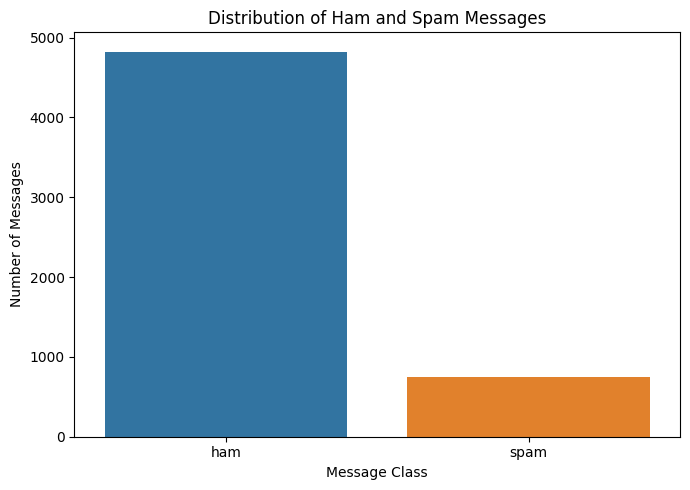

In [4]:
print("Unique labels:")
print(df["label"].unique())

label_counts = df["label"].value_counts()

print("\nClass counts:")
print(label_counts)

print("\nClass percentages:")
print((df["label"].value_counts(normalize=True) * 100).round(2))

# Visualise class distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="label", hue="label", legend=False)

plt.title("Distribution of Ham and Spam Messages")
plt.xlabel("Message Class")
plt.ylabel("Number of Messages")
plt.tight_layout()
plt.show()


#5. Check the missing values , duplicates and data quality

In [5]:

# Cell 5: Data quality checks

print("Missing values per column:")
print(df.isnull().sum())

print("\nCompletely duplicated rows:")
print(df.duplicated().sum())

print("\nDuplicated message texts:")
print(df["message"].duplicated().sum())

print("\nEmpty or whitespace-only messages:")
print(df["message"].str.strip().eq("").sum())

print("\nUnexpected labels:")
print(sorted(set(df["label"].unique()) - {"ham", "spam"}))


Missing values per column:
label      0
message    0
dtype: int64

Completely duplicated rows:
403

Duplicated message texts:
403

Empty or whitespace-only messages:
0

Unexpected labels:
[]
